# **Decision Tree using the Permit Score Dataset: Depth, Pruning, and Generalization**

This notebook provides a clear, end-to-end tutorial on how to train, tune, and
evaluate a **Decision Tree Classifier** using the *Permit Score* dataset.
The goal is to demonstrate not just model training, but also how to control
model complexity, avoid overfitting, and interpret the resulting performance.

By the end of this tutorial, you will be able to:

- load and explore a real dataset of permit scores,
- build a clean scikit-learn **pipeline** combining preprocessing and a decision tree,
- compare performance against a simple **baseline classifier**,
- analyze how tree depth affects training and generalization performance,
- use **cross-validation** and **cost-complexity pruning** to select an optimal depth,
- visualize metrics through accuracy curves, confusion matrices, and learning curves,
- interactively explore `max_depth` using a slider to understand model behavior.

---

## How to use this notebook

1. Run each cell from top to bottom—later sections rely on earlier computations.  
2. Read the explanation *above each code block* to understand the purpose and outcome.  
3. When you see an interactive tool or visualisation, experiment with it to deepen your understanding.  
4. Use this notebook as a template for building and tuning decision tree models on other datasets.

This structure ensures the tutorial is **readable**, **reproducible**, and easy to follow for both new learners and experienced practitioners.


# **1. Imports, Configuration, and Data Loading**

In this opening section, we prepare the environment for the rest of the tutorial by:

- importing the core scientific Python libraries (`numpy`, `pandas`, `matplotlib`, `seaborn`),
- importing the **scikit-learn** components required for preprocessing, model training, cross-validation, and evaluation,
- defining several global configuration values, including  
  - `RANDOM_STATE` to ensure reproducible results,  
  - `TEST_SIZE` to determine the size of the held-out test split, and  
  - `MAX_DEPTH_RANGE`, the range of tree depths to be examined in later sections.

We then load the *Permit Score* dataset from a CSV file into a `pandas.DataFrame`.  
After loading, we print the dataset’s shape and preview the first few rows to verify that the data has been read correctly and that the expected columns are present.

This setup provides a clean, well-defined starting point for the modelling workflow that follows.


In [ ]:
# 1. Imports, configuration, and data loading

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, learning_curve
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# Configuration
RANDOM_STATE = 42
TEST_SIZE = 0.25
MAX_DEPTH_RANGE = range(1, 15)

plt.rcParams["figure.figsize"] = (12, 7)

# Load the CSV file
df = pd.read_csv("Table4_simplified_permit_scores.csv")

print("Shape:", df.shape)
df

Shape: (175, 4)


,Document_ID,AHJ_Name,AHJ_State,Score
0,AL_01047_00000_01,"Dallas County, AL",AL,1
1,CA_06005_00000_01,"Amador County, CA",CA,3
2,CA_06005_00000_02,"Amador County, CA",CA,1
3,CA_06011_00000_01,"Colusa County, CA",CA,2
4,CA_06023_00000_01,"Humboldt County, CA",CA,2
...,...,...,...,...
170,WA_53053_00800_01,"Gig Harbor, WA",WA,2
171,WA_53053_02230_01,"Tacoma, WA",WA,3
172,WA_53061_00080_01,"Arlington, WA",WA,1
173,WI_55079_03100_01,"Milwaukee, WI",WI,2


# **2. Quick Exploration of the Data**

Before training any model, it is essential to gain a basic understanding of the dataset.
In this section, we perform a brief **exploratory data analysis (EDA)** to verify that the
data is clean and suitable for modelling.

Specifically, we:

- use `df.info()` to inspect the column types and check for missing values,
- examine the distribution of the target variable (`Score`) through simple counts and a bar plot,
- review basic summary statistics to confirm that the data behaves as expected.

This early inspection allows us to detect potential issues—such as **class imbalance**, inconsistent data types, or unexpected categories—that could influence how we preprocess the data and how well a decision tree can learn from it.

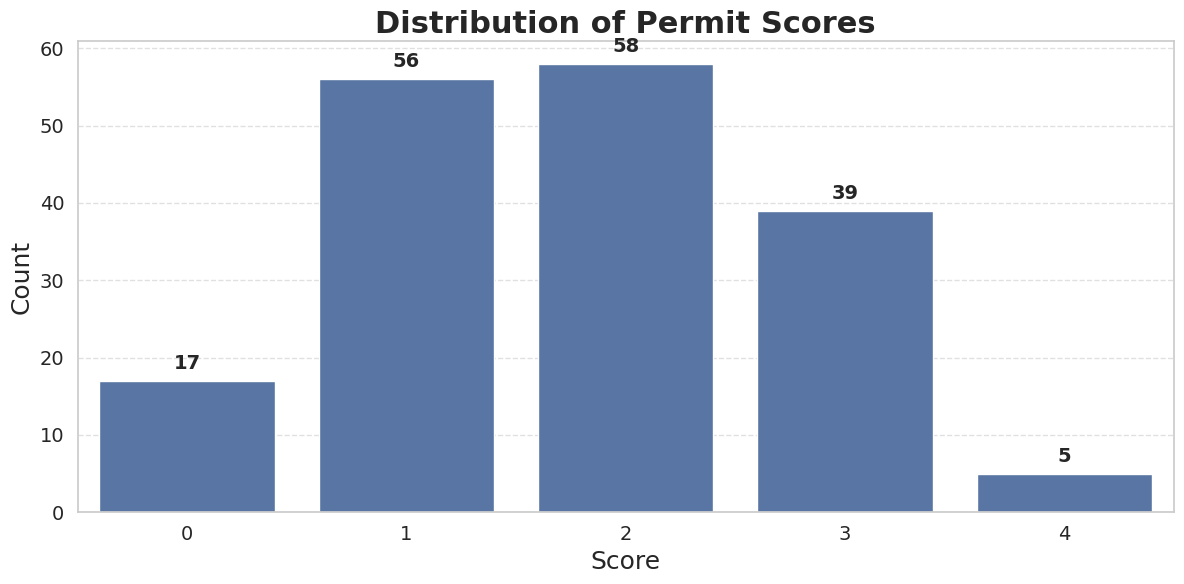

In [ ]:
# 2. Quick exploration of the data

import matplotlib.pyplot as plt
import seaborn as sns

# Use a clean Seaborn style
sns.set_theme(style="whitegrid")

# Compute value counts
value_counts = df["Score"].value_counts().sort_index()

plt.figure(figsize=(12, 6))


barplot = sns.barplot(
    x=value_counts.index,
    y=value_counts.values
)

plt.title("Distribution of Permit Scores", fontsize=22, weight="bold")
plt.xlabel("Score", fontsize=18)
plt.ylabel("Count", fontsize=18)
plt.xticks(rotation=0, fontsize=14)
plt.yticks(fontsize=14)

# value annotations
for i, v in enumerate(value_counts.values):
    plt.text(
        i,
        v + 1,
        str(v),
        ha="center", va="bottom",
        fontsize=14, weight="semibold"
    )


plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


# **3. Define Features (X) and Target (y)**

In this step, we formally separate the **predictor variables** from the **target
variable** that the decision tree will learn to classify.

- `feature_cols` specifies the columns used as inputs to the model.
- `target_col` identifies the outcome we aim to predict (`Score`).

We then construct:
- `X`, a DataFrame containing only the input features, and  
- `y`, a Series containing the target labels.

We also distinguish between **categorical** and **numerical** features, which is important
because they require different preprocessing (e.g., one-hot encoding for categorical variables).

Defining the features and target explicitly ensures clarity and makes the preprocessing and modelling pipeline easier to manage and reuse later in the workflow.


In [ ]:
## 3. Define features (X) and target (y)

#define target and feature columns
target_col = "Score"
feature_cols = ["AHJ_Name", "AHJ_State"]

X = df[feature_cols].copy()
y = df[target_col].copy()

# Identify categorical vs numerical columns
categorical_cols = [c for c in feature_cols if df[c].dtype == "object"]
numeric_cols = [c for c in feature_cols if c not in categorical_cols]

print("Target column:", target_col)
print("\nFeature columns:", feature_cols)
print("Categorical:", categorical_cols if categorical_cols else "None")
print("Numerical  :", numeric_cols if numeric_cols else "None")

# feature summary
feature_summary = (
    df[feature_cols]
    .agg(["nunique"])
    .T.rename(columns={"nunique": "n_unique"})
)

feature_summary["dtype"] = [df[c].dtype for c in feature_summary.index]
feature_summary["role"] = [
    "categorical" if col in categorical_cols else "numeric"
    for col in feature_summary.index
]

print("\nFeature summary:")
print(feature_summary[["role", "dtype", "n_unique"]].to_string())


Target column: Score

Feature columns: ['AHJ_Name', 'AHJ_State']
Categorical: ['AHJ_Name', 'AHJ_State']
Numerical  : None

Feature summary:
                  role   dtype  n_unique
AHJ_Name   categorical  object       160
AHJ_State  categorical  object        39


# **4. Train–Test Split**

To obtain a reliable estimate of how well the model will generalize to unseen data,
we create a dedicated **test set** that is kept completely separate from the model
training and hyper-parameter tuning process.

Using `train_test_split`:

- we divide the dataset into training and test subsets,
- we enable `stratify=y` to preserve the original class distribution in both splits,
- and we rely on the train portion (`X_train`, `y_train`) for all modelling steps that follow.

Only after we finish cross-validation, depth selection, and pruning do we evaluate the final model on the untouched test set.  
This approach ensures a fair and unbiased assessment of real-world performance.


In [ ]:
## 4. Train–test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

#small summary table
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "n_samples": [len(X_train), len(X_test)],
    "Percentage": [
        f"{len(X_train) / len(df):.1%}",
        f"{len(X_test) / len(df):.1%}"
    ]
})

print("\n Train–test split completed:")
display(
    split_summary.style
    .hide(axis="index")
    .set_table_attributes('style="border-collapse: collapse; width: 40%;"')
    .set_caption("Dataset Split Overview")
)


 Train–test split completed:


Dataset,n_samples,Percentage
Train,131,74.9%
Test,44,25.1%


# **5. Baseline Model, Preprocessing Pipeline, and Tree Visualisation**

Before building a fully tuned decision tree, we start by establishing a simple
baseline and setting up a clean preprocessing workflow. We also introduce a
visualisation step to better understand how the tree makes decisions.

---

### **1. Baseline (Most-Frequent Class Classifier)**  
We begin with a dummy classifier that always predicts the most common class in
the training set.  
This baseline provides a **minimum performance benchmark**—any useful decision
tree should outperform it in terms of both accuracy and macro-averaged F1 score.

---

### **2. Preprocessing Pipeline**  
We then construct a preprocessing pipeline using `ColumnTransformer` and
`OneHotEncoder` to convert categorical variables into a numerical format required
by scikit-learn estimators.  
Numerical columns (if present) are passed through unchanged.

By integrating preprocessing directly into the pipeline, we guarantee that:

- encoding is applied consistently,
- the model never sees unprocessed data,
- and data leakage is avoided.

This same pipeline will later be reused across all experiments, including
depth-tuning and pruning.

---

### **3. Decision Tree Visualisation**  
After fitting the preprocessing + decision tree pipeline, we extract:

- the encoded feature names,  
- the class labels learned by the model, and  
- the trained decision tree itself.

We then use `sklearn.tree.plot_tree` to generate a **fully visualised diagram of
the decision tree**, including:

- split conditions,  
- class predictions,  
- Gini impurity values, and  
- sample counts.

This visualisation helps us interpret how the tree uses categorical features
(such as AHJ_Name and AHJ_State) to predict a permit score.  
It also provides an early sense of tree complexity—useful when evaluating
overfitting later in the notebook.


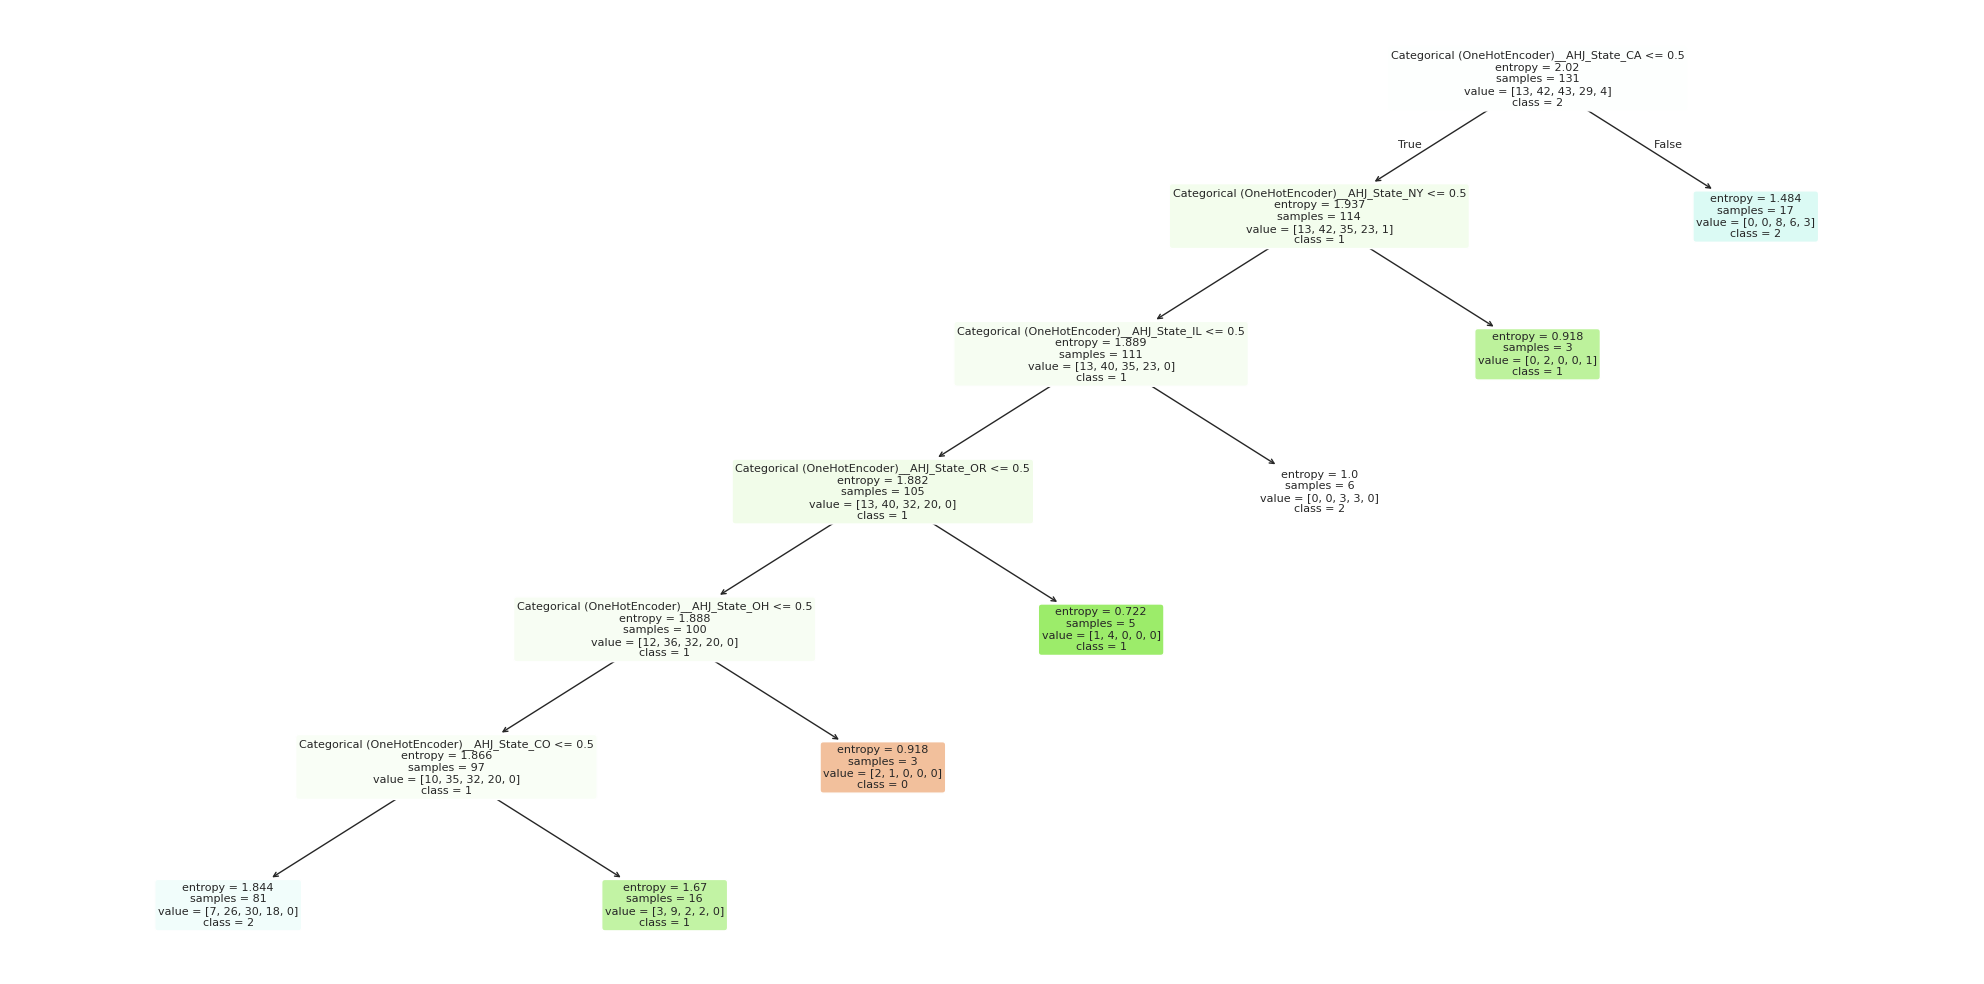

In [ ]:
#5. Baseline model and preprocessing pipeline

from sklearn import tree
import matplotlib.pyplot as plt

# 1. Fit the pipeline on your training data
tree_pipe.fit(X_train, y_train)

# 2. Get feature and class names
feature_names = tree_pipe.named_steps["Preprocessing"].get_feature_names_out()
class_names = tree_pipe.named_steps["DecisionTreeClassifier"].classes_.astype(str)

# 3. Plot the tree
plt.figure(figsize=(20, 10))
tree.plot_tree(
    tree_pipe.named_steps["DecisionTreeClassifier"],
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    proportion=False,   # set True if you prefer proportions
    fontsize=8
)
plt.tight_layout()
plt.show()

# **6. Base Decision Tree Model (No Depth Limit)**

We begin our modelling experiments by training an unconstrained
**DecisionTreeClassifier**, where `max_depth` is left unspecified.  
This allows the tree to grow as deep as needed to perfectly fit—or even
memorize—the training data.

The model is embedded inside the same preprocessing pipeline defined earlier,
ensuring that one-hot encoding is applied consistently and correctly.

After training, we evaluate performance on both the training and test sets.
The contrast between these two scores provides an early indication of
**overfitting**: deep decision trees commonly achieve near-perfect training
accuracy, but their generalisation performance may degrade when evaluated on
unseen data.



Overall performance:
Dataset  Accuracy  Macro F1
  Train     0.969     0.970
   Test     0.273     0.183

Detailed classification report (Test set):
              precision    recall  f1-score   support

           0      0.000     0.000     0.000         4
           1      0.556     0.357     0.435        14
           2      0.308     0.267     0.286        15
           3      0.143     0.300     0.194        10
           4      0.000     0.000     0.000         1

    accuracy                          0.273        44
   macro avg      0.201     0.185     0.183        44
weighted avg      0.314     0.273     0.280        44



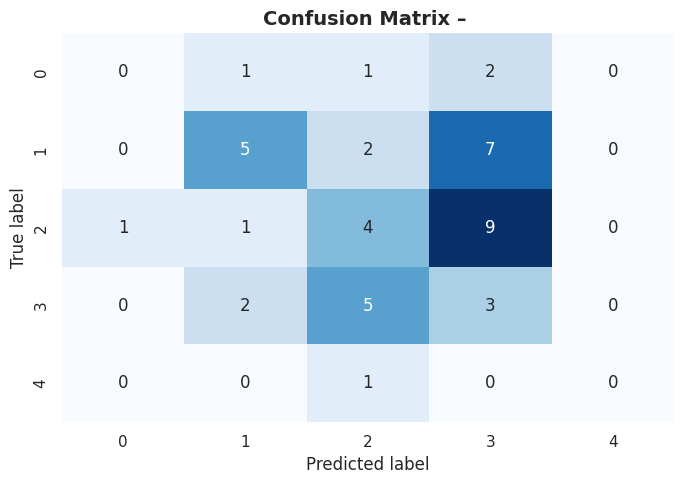

In [ ]:
# 6. Base decision tree model(no depth limit)

from sklearn.metrics import confusion_matrix # Added import

def evaluate_model(model: Pipeline, X_train, y_train, X_test, y_test, label: str = ""):

    # Fit model
    model.fit(X_train, y_train)

    # Make predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Scalar metrics
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    train_macro_f1 = f1_score(y_train, y_train_pred, average="macro", zero_division=0)
    test_macro_f1 = f1_score(y_test, y_test_pred, average="macro", zero_division=0)

    # Metrics table
    metrics_df = pd.DataFrame(
        {
            "Dataset": ["Train", "Test"],
            "Accuracy": [train_acc, test_acc],
            "Macro F1": [train_macro_f1, test_macro_f1],
        }
    )

    print("\nOverall performance:")
    print(metrics_df.to_string(index=False,
                               float_format=lambda x: f"{x:.3f}"))

    # Classification report
    print("\nDetailed classification report (Test set):")
    print(classification_report(y_test, y_test_pred, digits=3, zero_division=0))

    # Confusion matrix heatmap
    cm = confusion_matrix(y_test, y_test_pred)
    labels = sorted(pd.unique(y_test))

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        cbar=False
    )
    plt.title(f"Confusion Matrix – {label}", fontsize=14, weight="bold")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.tight_layout()
    plt.show()


    return {
        "model": model,
        "y_pred_train": y_train_pred,
        "y_pred_test": y_test_pred,
        "train_acc": train_acc,
        "test_acc": test_acc,
        "train_macro_f1": train_macro_f1, # Changed to return both train and test macro F1
        "test_macro_f1": test_macro_f1,
    }
base_tree = build_tree_pipeline(max_depth=None)

metrics_base = evaluate_model(
    model=base_tree,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    label=""
)

# **7. Exploring the Effect of `max_depth`**

To understand how model complexity influences performance, we systematically
vary the decision tree’s `max_depth` and observe how both training and test
accuracy behave.

For each depth in `MAX_DEPTH_RANGE`, we:

- construct a fresh pipeline with that specific depth,
- train the model on the training data,
- compute training accuracy, test accuracy, and macro-averaged F1 score.

These results allow us to visualise how performance evolves as the tree becomes
larger and more expressive.  
This forms a practical, hands-on version of a **validation curve**, highlighting
key patterns such as underfitting at low depths and overfitting at very large
depths.



Summary table (sorted by test Macro F1):
 max_depth  train_accuracy  test_accuracy  train_macro_F1  test_macro_F1
         5           0.473          0.432           0.495          0.204
         3           0.427          0.432           0.353          0.201
         4           0.443          0.432           0.397          0.201
         6           0.527          0.386           0.550          0.169
         9           0.626          0.386           0.677          0.169
         7           0.550          0.386           0.572          0.169
        14           0.710          0.386           0.774          0.169
        11           0.664          0.386           0.733          0.169
        10           0.649          0.295           0.709          0.145
         8           0.588          0.295           0.617          0.145
        12           0.679          0.295           0.754          0.145
        13           0.695          0.295           0.763          0.145
         

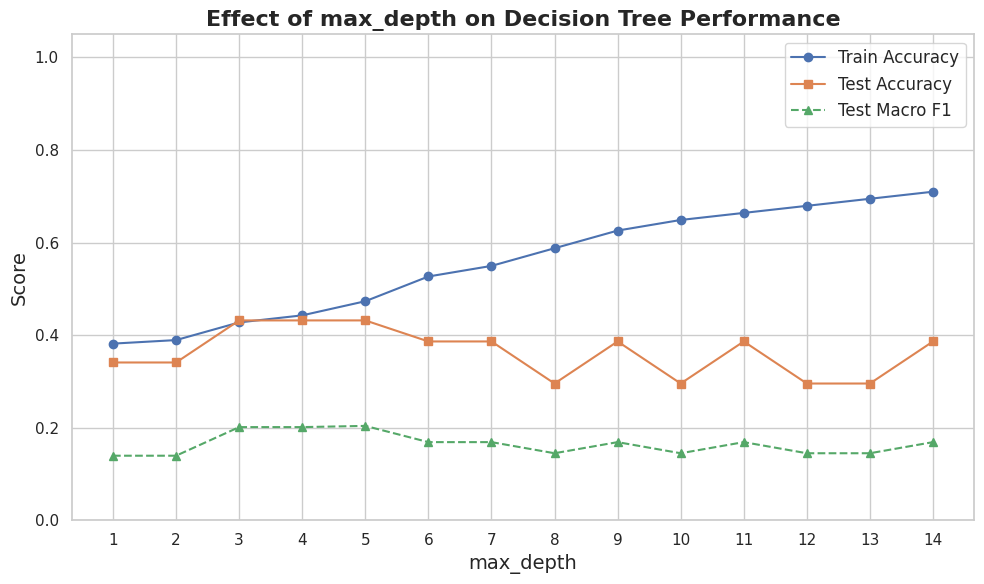

In [ ]:
# 7. Exploring the effect of `max_depth`

depths = list(MAX_DEPTH_RANGE)

results = {
    "max_depth": [],
    "train_accuracy": [],
    "test_accuracy": [],
    "train_macro_F1": [],
    "test_macro_F1": [],
}

for d in depths:
    model = build_tree_pipeline(max_depth=d)
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    results["max_depth"].append(d)
    results["train_accuracy"].append(accuracy_score(y_train, y_train_pred))
    results["test_accuracy"].append(accuracy_score(y_test, y_test_pred))
    results["train_macro_F1"].append(f1_score(y_train, y_train_pred, average="macro"))
    results["test_macro_F1"].append(f1_score(y_test, y_test_pred, average="macro"))

# Put everything into a nice DataFrame
results_df = pd.DataFrame(results)

# Find depth with best test Macro F1
best_row = results_df.loc[results_df["test_macro_F1"].idxmax()]

print("\nSummary table (sorted by test Macro F1):")
print(
    results_df.sort_values("test_macro_F1", ascending=False)
    .reset_index(drop=True)
    .to_string(index=False, float_format=lambda x: f"{x:.3f}")
)

print("\nBest depth based on test Macro F1:")
print(
    f"  max_depth = {int(best_row['max_depth'])} | "
    f"Test Accuracy = {best_row['test_accuracy']:.3f}, "
    f"Test Macro F1 = {best_row['test_macro_F1']:.3f}"
)

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
plt.plot(results_df["max_depth"], results_df["train_accuracy"],
         marker="o", linestyle="-", label="Train Accuracy")
plt.plot(results_df["max_depth"], results_df["test_accuracy"],
         marker="s", linestyle="-", label="Test Accuracy")
plt.plot(results_df["max_depth"], results_df["test_macro_F1"],
         marker="^", linestyle="--", label="Test Macro F1")

plt.title("Effect of max_depth on Decision Tree Performance", fontsize=16, weight="bold")
plt.xlabel("max_depth", fontsize=14)
plt.ylabel("Score", fontsize=14)
plt.xticks(depths)
plt.ylim(0.0, 1.05)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()


# **8. Plot: Depth vs Performance**

With the metrics computed for each candidate depth, we now visualise how model
performance changes as the decision tree becomes deeper.

We plot both the **training** and **test** accuracy curves (and likewise for
macro-averaged F1), which reveal the characteristic behaviour of decision trees:

- **Shallow trees** (low `max_depth`) typically *underfit*, leading to low scores on both
  the training and test sets.
- **Very deep trees** tend to *overfit*: training accuracy approaches 1.0, while
  test performance begins to degrade.
- Between these extremes, there is usually an intermediate depth that strikes a
  good balance between bias and variance.

By examining these curves, we can visually identify the depth that offers the
best generalisation performance; this candidate will be carried forward in the
next stages of the analysis.


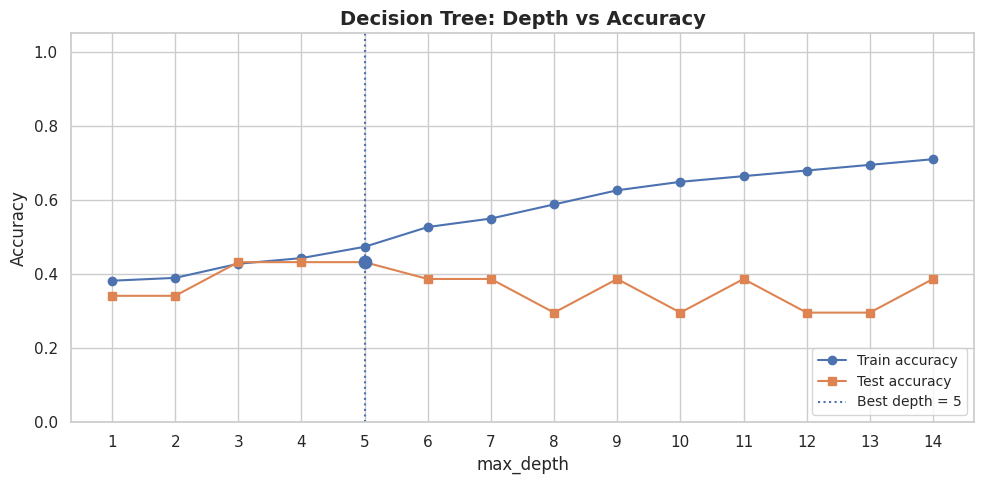

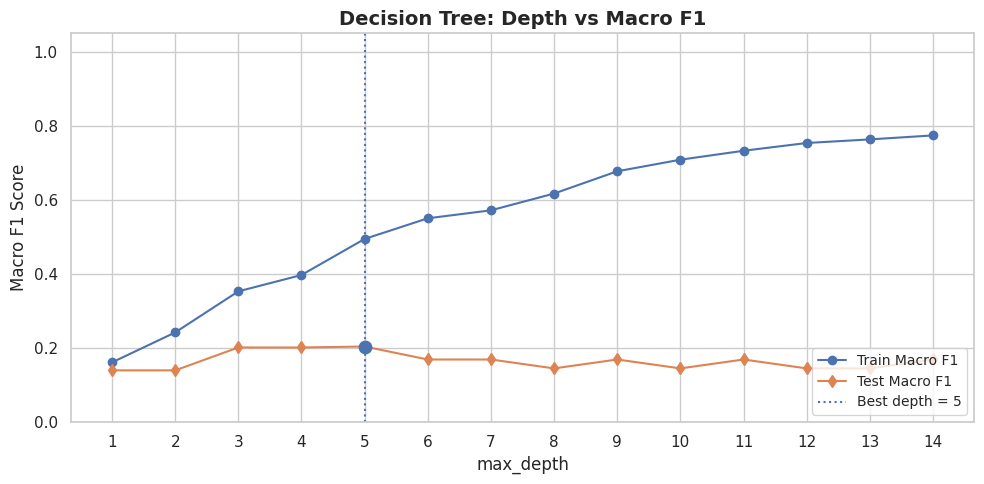


Best depth by test Macro F1:
  max_depth = 5
  Test accuracy = 0.432
  Test macro F1 = 0.204



In [ ]:
## 8. Plot: depth vs performance

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

sns.set_theme(style="whitegrid")

depths_array = results_df["max_depth"].values
train_accuracies = results_df["train_accuracy"].values
test_accuracies = results_df["test_accuracy"].values
train_macro_f1_scores = results_df["train_macro_F1"].values
test_macro_f1_scores = results_df["test_macro_F1"].values

# Find best depth based on test Macro F1
best_index = int(np.argmax(test_macro_f1_scores))
best_depth = depths_array[best_index]


# PLOT 1: Accuracy vs Depth (first line)
plt.figure(figsize=(10, 5))
plt.plot(depths_array, train_accuracies, marker="o", label="Train accuracy")
plt.plot(depths_array, test_accuracies, marker="s", label="Test accuracy")
plt.axvline(best_depth, linestyle=":", linewidth=1.5, label=f"Best depth = {best_depth}")
plt.scatter([best_depth], [test_accuracies[best_index]], s=80, zorder=5)

plt.title("Decision Tree: Depth vs Accuracy", fontsize=14, weight="bold")
plt.xlabel("max_depth", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xticks(depths_array)
plt.ylim(0, 1.05)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

# PLOT 2: Macro F1 vs Depth

plt.figure(figsize=(10, 5))
plt.plot(depths_array, train_macro_f1_scores, marker="o", label="Train Macro F1")
plt.plot(depths_array, test_macro_f1_scores, marker="d", label="Test Macro F1") # Use test_macro_f1_scores
plt.axvline(best_depth, linestyle=":", linewidth=1.5, label=f"Best depth = {best_depth}")
plt.scatter([best_depth], [test_macro_f1_scores[best_index]], s=80, zorder=5) # Use test_macro_f1_scores

plt.title("Decision Tree: Depth vs Macro F1", fontsize=14, weight="bold")
plt.xlabel("max_depth", fontsize=12)
plt.ylabel("Macro F1 Score", fontsize=12)
plt.xticks(depths_array)
plt.ylim(0, 1.05)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()


# SUMMARY TEXT
print("\nBest depth by test Macro F1:") # Updated descriptive text
print(f"  max_depth = {best_depth}")
print(f"  Test accuracy = {test_accuracies[best_index]:.3f}")
print(f"  Test macro F1 = {test_macro_f1_scores[best_index]:.3f}\n") # Use test_macro_f1_scores


# **9. Train Final Model and Inspect Confusion Matrix**

After selecting an appropriate `max_depth`, we retrain a decision tree using the
entire training set and evaluate its performance on the held-out test set.

In this step, we:

- compute the final test accuracy and macro-averaged F1 score, and
- visualise the **confusion matrix** to examine how well the model distinguishes
  between individual classes.

The confusion matrix provides class-level insight by revealing which categories
are correctly identified and which tend to be misclassified.  
This is especially valuable when class frequencies are uneven, since overall
accuracy alone may hide important patterns in per-class performance.


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklea

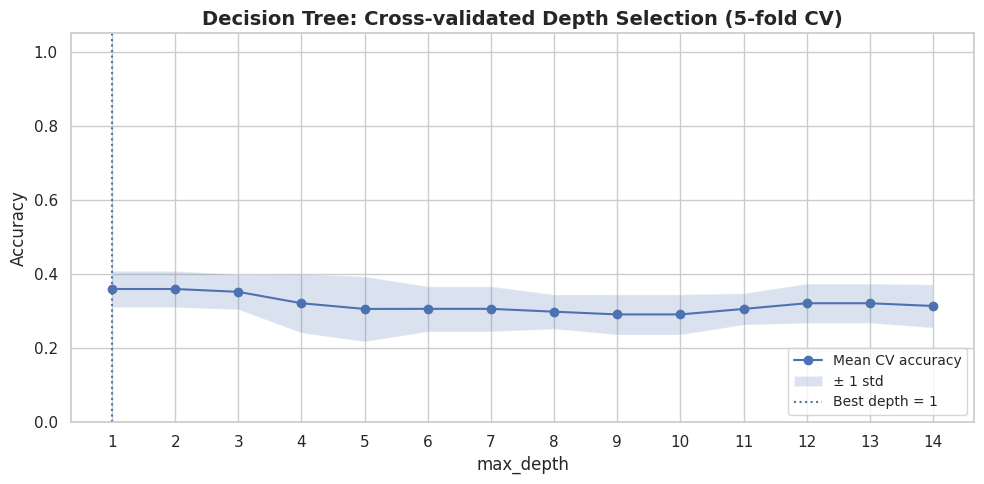


Cross-validated accuracy by depth (sorted by mean CV accuracy):
 max_depth  cv_mean_accuracy  cv_std_accuracy
         1             0.359            0.049
         2             0.359            0.049
         3             0.352            0.047
         4             0.321            0.080
        12             0.321            0.053
        13             0.321            0.053
        14             0.313            0.058
         6             0.306            0.061
         7             0.306            0.061
         5             0.305            0.088
        11             0.305            0.042
         8             0.298            0.046
        10             0.291            0.054
         9             0.291            0.054

Best depth selected by 5-fold CV accuracy:
  max_depth = 1  |  mean accuracy = 0.359  ± 0.049


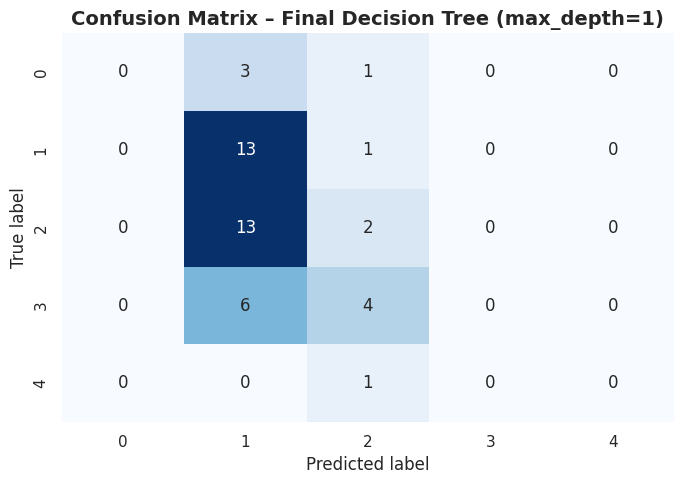


Classification report for final model (test set):
              precision    recall  f1-score   support

           0      0.000     0.000     0.000         4
           1      0.371     0.929     0.531        14
           2      0.222     0.133     0.167        15
           3      0.000     0.000     0.000        10
           4      0.000     0.000     0.000         1

    accuracy                          0.341        44
   macro avg      0.119     0.212     0.139        44
weighted avg      0.194     0.341     0.226        44



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# 9. Train final model and inspect confusion matrix

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = {
    "max_depth": [],
    "cv_mean_accuracy": [],
    "cv_std_accuracy": [],
}

for d in depths:
    model = build_tree_pipeline(max_depth=d)
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=None,
    )
    cv_results["max_depth"].append(d)
    cv_results["cv_mean_accuracy"].append(scores.mean())
    cv_results["cv_std_accuracy"].append(scores.std())

cv_df = pd.DataFrame(cv_results)


# Identify best depth by CV accuracy

best_cv_row = cv_df.loc[cv_df["cv_mean_accuracy"].idxmax()]
best_cv_depth = int(best_cv_row["max_depth"])

# Pretty CV plot

sns.set_theme(style="whitegrid")

depths_array = cv_df["max_depth"].values
mean_acc = cv_df["cv_mean_accuracy"].values
std_acc = cv_df["cv_std_accuracy"].values

plt.figure(figsize=(10, 5))
plt.plot(depths_array, mean_acc, marker="o", label="Mean CV accuracy")
plt.fill_between(
    depths_array,
    mean_acc - std_acc,
    mean_acc + std_acc,
    alpha=0.2,
    label="± 1 std",
)

# highlight chosen depth
plt.axvline(best_cv_depth, linestyle=":", linewidth=1.5,
            label=f"Best depth = {best_cv_depth}")

plt.title("Decision Tree: Cross-validated Depth Selection (5-fold CV)",
          fontsize=14, weight="bold")
plt.xlabel("max_depth", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xticks(depths_array)
plt.ylim(0, 1.05)
plt.legend(loc="lower right", fontsize=10)
plt.tight_layout()
plt.show()

# CV results table + summary text

print("\nCross-validated accuracy by depth (sorted by mean CV accuracy):")
print(
    cv_df.sort_values("cv_mean_accuracy", ascending=False)
    .reset_index(drop=True)
    .to_string(index=False, float_format=lambda x: f"{x:.3f}")
)

print("\nBest depth selected by 5-fold CV accuracy:")
print(
    f"  max_depth = {best_cv_depth}  |  "
    f"mean accuracy = {best_cv_row['cv_mean_accuracy']:.3f}  "
    f"± {best_cv_row['cv_std_accuracy']:.3f}"
)


# Train final model at best depth and inspect confusion matrix

final_model = build_tree_pipeline(max_depth=best_cv_depth)
final_model.fit(X_train, y_train)
y_test_pred = final_model.predict(X_test)

cm = confusion_matrix(y_test, y_test_pred)
class_labels = sorted(pd.unique(y_test))

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels,
    cbar=False,
)
plt.title(f"Confusion Matrix – Final Decision Tree (max_depth={best_cv_depth})",
          fontsize=14, weight="bold")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

print("\nClassification report for final model (test set):")
print(classification_report(y_test, y_test_pred, digits=3))


# **10. Cost-complexity pruning path**

Scikit‑learn implements **cost‑complexity pruning**, a way to simplify an already‑grown tree by penalising the number of leaves.

In this section we:

- obtain the pruning path via `cost_complexity_pruning_path`, which gives us a sequence of `ccp_alpha` values,
- train a series of pruned trees for different `ccp_alpha`, and
- evaluate their cross‑validated performance.

This provides a second, more principled way to control model complexity in addition to `max_depth`.


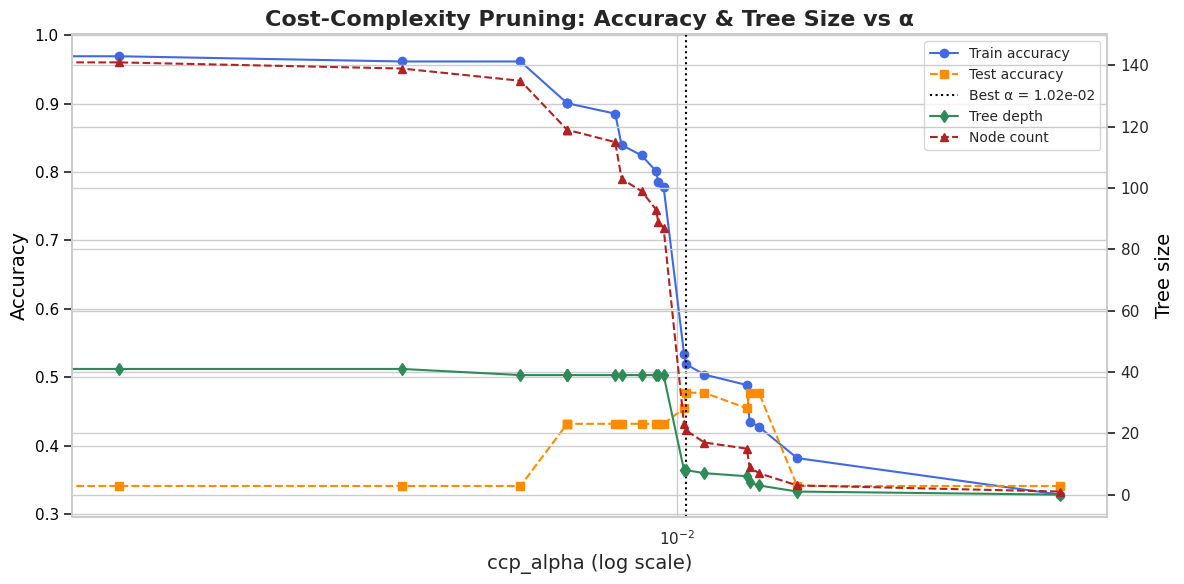


Best pruned tree selected by test accuracy:
  ccp_alpha = 1.02e-02  |  train acc = 0.519,  test acc = 0.477,  depth = 8,  nodes = 21


In [ ]:
# 10. Cost-complexity pruning path

from sklearn.tree import DecisionTreeClassifier
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Fit preprocessing and encode train / test once
preprocess_ccp = preprocess.fit(X_train, y_train)
X_train_enc = preprocess_ccp.transform(X_train)
X_test_enc = preprocess_ccp.transform(X_test)

# Compute pruning path on the encoded training data
clf_for_path = DecisionTreeClassifier(random_state=RANDOM_STATE)
path = clf_for_path.cost_complexity_pruning_path(X_train_enc, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

pruned_clfs = []
train_scores_ccp = []
test_scores_ccp = []
tree_depths = []
node_counts = []

for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=ccp_alpha)
    clf.fit(X_train_enc, y_train)

    train_scores_ccp.append(clf.score(X_train_enc, y_train))
    test_scores_ccp.append(clf.score(X_test_enc, y_test))
    tree_depths.append(clf.get_depth())
    node_counts.append(clf.tree_.node_count)
    pruned_clfs.append(clf)

# Put results into a DataFrame (nice for debugging / tables in report)
ccp_df = pd.DataFrame({
    "ccp_alpha": ccp_alphas,
    "train_accuracy": train_scores_ccp,
    "test_accuracy": test_scores_ccp,
    "depth": tree_depths,
    "node_count": node_counts,
})

# Best alpha by test accuracy
best_alpha_row = ccp_df.loc[ccp_df["test_accuracy"].idxmax()]
best_alpha = float(best_alpha_row["ccp_alpha"])

# Accuracy + Tree Size vs ccp_alpha

sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(12, 6))

# Accuracy curves
ax1.set_xscale("log")
ax1.plot(ccp_alphas, train_scores_ccp,
         marker="o", label="Train accuracy", color="royalblue")
ax1.plot(ccp_alphas, test_scores_ccp,
         marker="s", linestyle="--", label="Test accuracy", color="darkorange")
ax1.axvline(best_alpha, linestyle=":", color="black",
            label=f"Best α = {best_alpha:.2e}")

ax1.set_xlabel("ccp_alpha (log scale)", fontsize=14)
ax1.set_ylabel("Accuracy", fontsize=14, color="black")
ax1.tick_params(axis="y", labelcolor="black")

# Second y-axis for tree size
ax2 = ax1.twinx()
ax2.plot(ccp_alphas, tree_depths,
         marker="d", label="Tree depth", color="seagreen")
ax2.plot(ccp_alphas, node_counts,
         marker="^", linestyle="--", label="Node count", color="firebrick")
ax2.set_ylabel("Tree size", fontsize=14, color="black")

# Combined legend from both axes
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2,
           loc="best", fontsize=10)

plt.title("Cost-Complexity Pruning: Accuracy & Tree Size vs α",
          fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

# summary
print("\nBest pruned tree selected by test accuracy:")
print(
    f"  ccp_alpha = {best_alpha:.2e}  |  "
    f"train acc = {best_alpha_row['train_accuracy']:.3f},  "
    f"test acc = {best_alpha_row['test_accuracy']:.3f},  "
    f"depth = {int(best_alpha_row['depth'])},  "
    f"nodes = {int(best_alpha_row['node_count'])}"
)




# **11. Learning Curves for the Selected Depth**

To examine how the model’s performance changes as we increase the amount of
training data, we compute **learning curves** for the chosen `max_depth`.

Using `learning_curve`, we:

- train the model on progressively larger subsets of the training data,
- measure both training accuracy and cross-validated validation accuracy at each size,
- and visualise how these scores evolve as more data becomes available.

Learning curves help diagnose whether the model is limited by **underfitting**,
**overfitting**, or simply by insufficient data.  
If the training and validation curves converge and flatten out, additional data
is unlikely to yield significant improvements.  
If a persistent gap remains between the curves, the model may still benefit from
more training examples or additional regularisation.


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


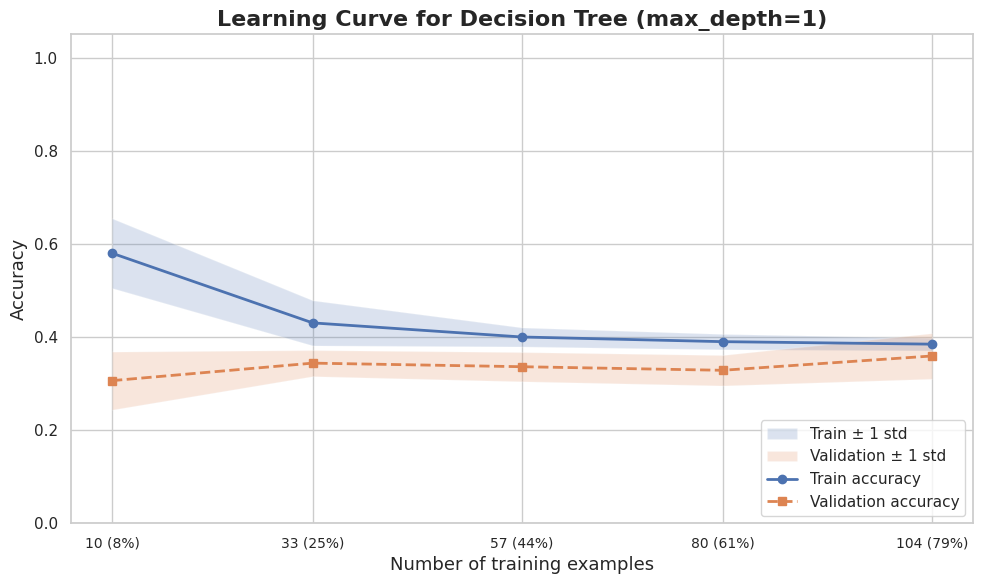

In [ ]:
# 11.Learning curves for the selected depth

from sklearn.model_selection import learning_curve
import seaborn as sns
import matplotlib.pyplot as plt

selected_depth = best_cv_depth
estimator = build_tree_pipeline(max_depth=selected_depth)

train_sizes, train_scores, val_scores = learning_curve(
    estimator,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=None,
    train_sizes=np.linspace(0.1, 1.0, 5),
    shuffle=True,
    random_state=RANDOM_STATE,
)

train_scores_mean = train_scores.mean(axis=1)
train_scores_std = train_scores.std(axis=1)
val_scores_mean = val_scores.mean(axis=1)
val_scores_std = val_scores.std(axis=1)

# Convert training sizes to nicer labels
n_train_total = len(X_train)
size_labels = [f"{n} ({n / n_train_total:.0%})" for n in train_sizes]

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
plt.fill_between(
    train_sizes,
    train_scores_mean - train_scores_std,
    train_scores_mean + train_scores_std,
    alpha=0.20,
    label="Train ± 1 std",
)
plt.fill_between(
    train_sizes,
    val_scores_mean - val_scores_std,
    val_scores_mean + val_scores_std,
    alpha=0.20,
    label="Validation ± 1 std",
)

# Mean lines
plt.plot(train_sizes, train_scores_mean, marker="o",
         linewidth=2, label="Train accuracy")
plt.plot(train_sizes, val_scores_mean, marker="s", linestyle="--",
         linewidth=2, label="Validation accuracy")

plt.title(f"Learning Curve for Decision Tree (max_depth={selected_depth})",
          fontsize=16, weight="bold")
plt.xlabel("Number of training examples", fontsize=13)
plt.ylabel("Accuracy", fontsize=13)
plt.ylim(0.0, 1.05)

# Use combined labels (n and %) for xticks
plt.xticks(train_sizes, size_labels, rotation=0, fontsize=10)

plt.legend(fontsize=11, loc="lower right")
plt.tight_layout()
plt.show()

# **12. Train Final Model and Inspect Confusion Matrix**

With the optimal depth selected (and any pruning decisions made), we now train
the final decision tree model using the complete training set.

In this step, we:

- fit the model using the chosen hyper-parameters,
- evaluate its performance on the untouched test set,
- and examine both the overall metrics and the **confusion matrix** to assess
  class-level behaviour.

This final evaluation represents the model’s true generalisation performance and
is the result we would report in a project summary or technical paper.  
The confusion matrix and classification report help us understand which classes
are predicted reliably and where the model still struggles.



Overall performance:
Dataset  Accuracy  Macro F1
  Train     0.382     0.161
   Test     0.341     0.139

Detailed classification report (Test set):
              precision    recall  f1-score   support

           0      0.000     0.000     0.000         4
           1      0.371     0.929     0.531        14
           2      0.222     0.133     0.167        15
           3      0.000     0.000     0.000        10
           4      0.000     0.000     0.000         1

    accuracy                          0.341        44
   macro avg      0.119     0.212     0.139        44
weighted avg      0.194     0.341     0.226        44



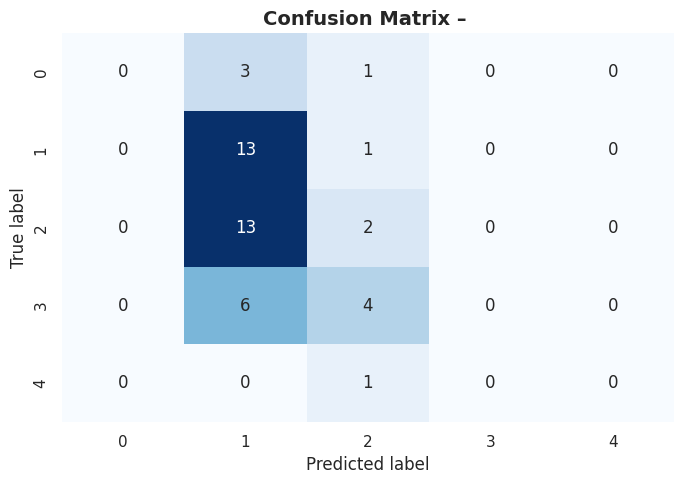

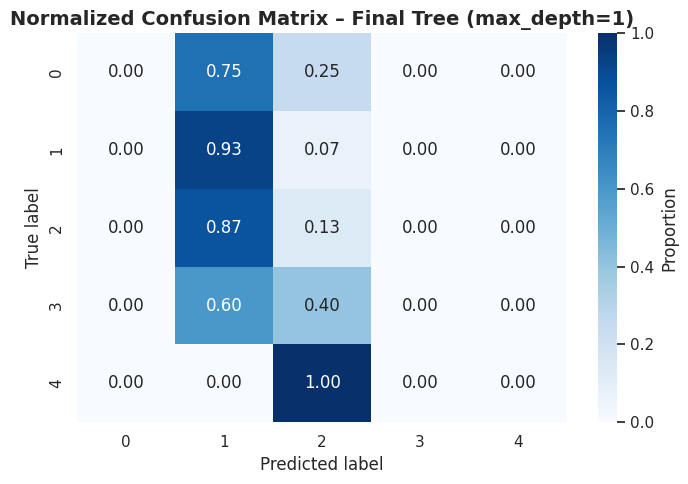


Detailed classification report for final model (test set):

              precision    recall  f1-score   support

           0      0.000     0.000     0.000         4
           1      0.371     0.929     0.531        14
           2      0.222     0.133     0.167        15
           3      0.000     0.000     0.000        10
           4      0.000     0.000     0.000         1

    accuracy                          0.341        44
   macro avg      0.119     0.212     0.139        44
weighted avg      0.194     0.341     0.226        44



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
# 12.Train final model and inspect confusion matrix
final_depth = selected_depth

final_clf = build_tree_pipeline(max_depth=final_depth)

metrics_final = evaluate_model(
    final_clf,
    X_train,
    y_train,
    X_test,
    y_test,
    label=""
)

y_best_pred = metrics_final["y_pred_test"]


# Normalized confusion matrix (percentages per true class)

labels = sorted(pd.unique(y_test))
cm = confusion_matrix(y_test, y_best_pred, labels=labels)
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    cbar_kws={"label": "Proportion"},
)

plt.title(f"Normalized Confusion Matrix – Final Tree (max_depth={final_depth})",
          fontsize=14, weight="bold")
plt.xlabel("Predicted label", fontsize=12)
plt.ylabel("True label", fontsize=12)
plt.tight_layout()
plt.show()


# Detailed classification report
print("\nDetailed classification report for final model (test set):\n")
print(classification_report(y_test, y_best_pred, digits=3))


# **13. Interactive Depth Explorer**

To make the behaviour of decision trees more intuitive, we conclude with a small
**interactive exploration tool** built using `ipywidgets`.

A slider allows you to vary the `max_depth` of the tree.  
For each selected depth, the notebook:

- rebuilds and retrains the decision-tree pipeline,
- reports training and test accuracy as well as macro-averaged F1,
- and displays a normalised confusion matrix for the test set.

This interactive view makes it easy to experiment with different complexity
levels and observe, in real time, how underfitting and overfitting manifest in
both the overall metrics and the per-class predictions.


In [ ]:
# 13. Interactive depth explorer

try:
    from ipywidgets import interact, IntSlider
    HAS_IPYWIDGETS = True
except ImportError:
    HAS_IPYWIDGETS = False

# Fallback message if ipywidgets is not installed
if not HAS_IPYWIDGETS:
    print(
        "ipywidgets is not installed. "
        "Install it with `pip install ipywidgets` to use the interactive slider."
    )

else:
    sns.set_theme(style="whitegrid")

    @interact(
        depth=IntSlider(
            min=1,
            max=15,
            step=1,
            value=final_depth,
            description="max_depth",
            continuous_update=False,
        )
    )
    def explore_depth(depth=final_depth):
        model = build_tree_pipeline(max_depth=depth)
        model.fit(X_train, y_train)

        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)

        # Compute train/test metrics (accuracy + macro F1)
        train_acc = accuracy_score(y_train, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        train_f1 = f1_score(y_train, y_train_pred, average="macro")
        test_f1 = f1_score(y_test, y_test_pred, average="macro")

        metrics_df = pd.DataFrame(
            {
                "Dataset": ["Train", "Test"],
                "Accuracy": [train_acc, test_acc],
                "Macro F1": [train_f1, test_f1],
            }
        )

        # Show title + compact metrics table
        display(HTML(f"<h3>Decision Tree Performance (max_depth = {depth})</h3>"))
        display(
            metrics_df.style
            .format({"Accuracy": "{:.3f}", "Macro F1": "{:.3f}"})
            .hide(axis="index")
            .set_table_attributes('style="border-collapse:collapse; width:50%;"')
        )

        # Plot normalized confusion matrix for test set
        labels = sorted(pd.unique(y_test))
        cm = confusion_matrix(y_test, y_test_pred, labels=labels)
        cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

        plt.figure(figsize=(6, 4))
        sns.heatmap(
            cm_norm,
            annot=True,
            fmt=".2f",
            cmap="Blues",
            xticklabels=labels,
            yticklabels=labels,
            cbar_kws={"label": "Proportion"},
        )
        plt.title("Normalized Confusion Matrix", fontsize=12, weight="bold")
        plt.xlabel("Predicted label")
        plt.ylabel("True label")
        plt.tight_layout()
        plt.show()

        # Detailed per-class metrics (precision/recall/F1)
        print("\nClassification report (test set):")
        print(classification_report(y_test, y_test_pred, digits=3))


interactive(children=(IntSlider(value=1, continuous_update=False, description='max_depth', max=15, min=1), Out…